# CNN: clasificación de enfermedades en hojas de frijol

## Objetivo
Implementar, entrenar y evaluar una red neuronal convolucional que clasifique fotografías de hojas de frijol en mancha angular, roya y sanas.

## Dataset y justificación
Beans fue recopilado por Makerere AI Lab con fotografías de campo y anotaciones de expertos de NaCRRI en Uganda. Es un problema agrícola real con variaciones de fondo, iluminación y aspecto de las lesiones.

- [Autores y licencia MIT](https://github.com/AI-Lab-Makerere/ibean)
- [Publicación utilizada en Hugging Face](https://huggingface.co/datasets/AI-Lab-Makerere/beans)
- [Descripción en TensorFlow Datasets](https://www.tensorflow.org/datasets/catalog/beans)

Se conservan 1,034 imágenes de entrenamiento, 133 de validación y 128 de prueba. La carga verifica estos tamaños; no se usa el conteo agregado del README original, que difiere del publicado en estas particiones.

## Metodología
Exploración, auditoría de imágenes y duplicados, redimensionamiento, normalización, comparación de dos CNN con y sin aumento, selección por validación y evaluación final en prueba. Ambas redes se entrenan desde cero: no se usan pesos preentrenados. Se incluyen curvas, resumen de arquitectura, métricas por clase, matriz de confusión, ejemplos de aciertos/errores y conclusiones.

## Cómo ejecutar
En Google Colab, ejecutar todas las celdas en orden desde la instalación. CPU es suficiente; entrenar ambas configuraciones puede tardar varios minutos. La descarga inicial requiere internet. Los archivos de modelos y métricas se generan en `/content/resultados_cnn`, ubicación temporal que no se incorpora automáticamente al guardar el notebook. Las salidas del notebook sí se conservan al guardarlo.

## Alcance
Proyecto académico: no es una herramienta de diagnóstico agrícola validada. No se ajustan configuraciones usando los resultados de prueba.

In [5]:
%pip -q install datasets Pillow

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import datasets as hf_datasets
from datasets import load_dataset
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__)
print('Hugging Face Datasets:', hf_datasets.__version__)
print('GPU disponibles:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
Hugging Face Datasets: 4.8.5
GPU disponibles: []


## 1. Carga del dataset

Se utiliza la publicación de Beans en [Hugging Face](https://huggingface.co/datasets/AI-Lab-Makerere/beans) enlazada por los autores, porque la descarga original utilizada por TensorFlow Datasets devolvió HTTP 403.

Se conservan las particiones de entrenamiento, validación y prueba de esa publicación y se comprueban sus tamaños.

Las imágenes se convierten a RGB y se presentan como datasets de TensorFlow, sin redimensionar ni normalizar todavía. En esta etapa solo se inspecciona el contenido de entrenamiento.

In [7]:
DATASET_ID = 'AI-Lab-Makerere/beans'
beans = load_dataset(DATASET_ID)

class_names = beans['train'].features['labels'].names
num_classes = len(class_names)
split_sizes = {split: len(beans[split]) for split in beans}
expected_sizes = {'train': 1034, 'validation': 133, 'test': 128}
assert split_sizes == expected_sizes, split_sizes

for split in expected_sizes:
    assert beans[split].features['labels'].names == class_names

def to_tensorflow(split):
    def generator():
        for example in beans[split]:
            image = np.asarray(example['image'].convert('RGB'), dtype=np.uint8)
            yield image, np.int64(example['labels'])

    return tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(None, None, 3), dtype=tf.uint8),
            tf.TensorSpec(shape=(), dtype=tf.int64)
        )
    ).apply(tf.data.experimental.assert_cardinality(split_sizes[split]))

train_raw = to_tensorflow('train')
val_raw = to_tensorflow('validation')
test_raw = to_tensorflow('test')

print('Clases:', class_names)
display(pd.DataFrame([
    {'Partición': split, 'Imágenes': size}
    for split, size in split_sizes.items()
]))
image, label = next(iter(train_raw))
print('Dimensiones de una imagen:', image.shape)
print('Tipo de dato:', image.dtype)
print('Rango de píxeles de esta imagen:', int(tf.reduce_min(image)), int(tf.reduce_max(image)))
print('Etiqueta de ejemplo:', class_names[int(label)])

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

... (3 outputs left out)

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

Clases: ['angular_leaf_spot', 'bean_rust', 'healthy']


,Partición,Imágenes
0,train,1034
1,validation,133
2,test,128


Dimensiones de una imagen: (500, 500, 3)
Tipo de dato: <dtype: 'uint8'>
Rango de píxeles de esta imagen: 0 255
Etiqueta de ejemplo: angular_leaf_spot


## 2. Exploración de clases e imágenes

Se contará la distribución de clases en entrenamiento y se
mostrarán tres ejemplos de cada clase, conservando sus colores
y dimensiones originales.

,Clase,Imágenes,Porcentaje
0,angular_leaf_spot,345,33.37
1,bean_rust,348,33.66
2,healthy,341,32.98


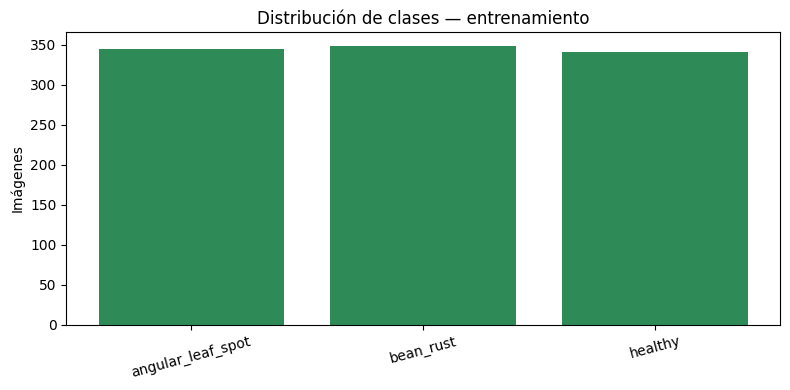

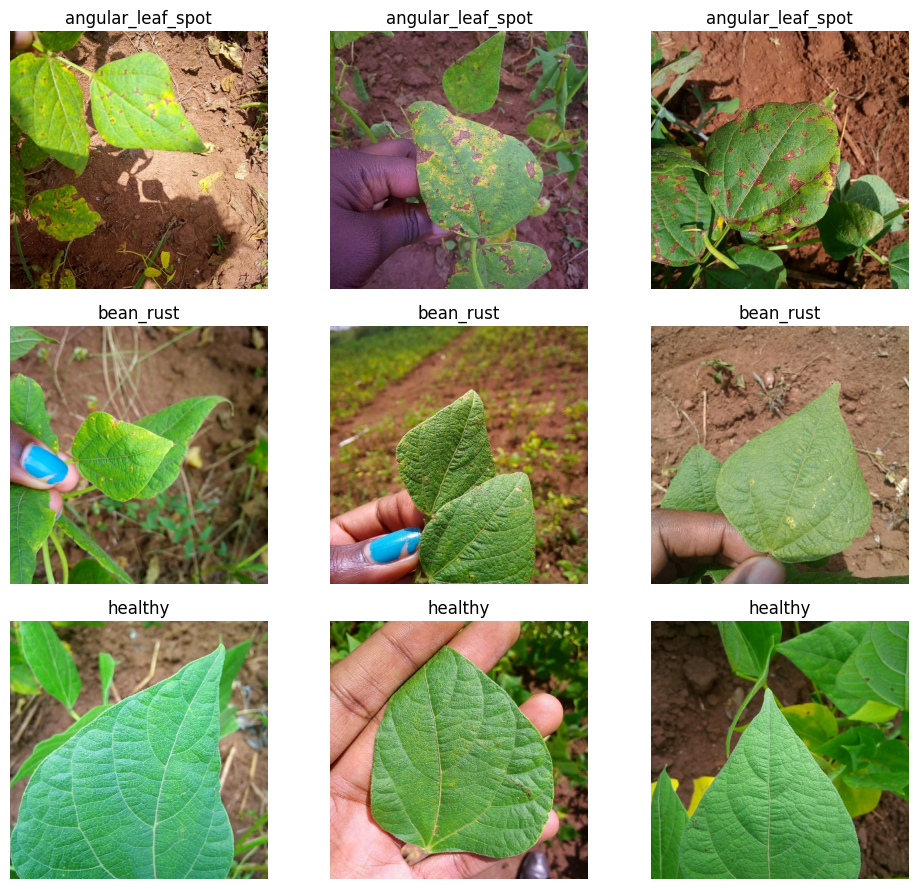

In [8]:
counts = np.zeros(num_classes, dtype=int)
examples = {i: [] for i in range(num_classes)}

for image, label in train_raw.as_numpy_iterator():
    class_id = int(label)
    counts[class_id] += 1
    if len(examples[class_id]) < 3:
        examples[class_id].append(image)

assert counts.sum() == split_sizes['train']
distribution = pd.DataFrame({
    'Clase': class_names,
    'Imágenes': counts,
    'Porcentaje': 100 * counts / counts.sum()
})
display(distribution.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_names, counts, color='seagreen')
ax.set(title='Distribución de clases — entrenamiento', ylabel='Imágenes')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(num_classes, 3, figsize=(10, 9))
for class_id in range(num_classes):
    for column in range(3):
        ax = axes[class_id, column]
        if column < len(examples[class_id]):
            ax.imshow(examples[class_id][column])
        ax.set_title(class_names[class_id])
        ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Preparación y control de calidad

Entrenamiento contiene 345 imágenes de mancha angular, 348 de roya y 341 sanas: las clases están aproximadamente equilibradas. Las fotografías muestran fondos, manos e iluminación variables; el modelo podría aprender señales ajenas a la enfermedad.

Se comprobará que todas las imágenes puedan decodificarse y tengan etiquetas válidas, y se buscarán duplicados exactos de píxeles dentro y entre particiones mediante SHA-256. Esta comprobación no detecta fotografías similares ni garantiza separación por planta o finca, información que no está disponible. Si existen duplicados entre particiones se detendrá el entrenamiento para revisar la división.

Las imágenes se redimensionan de 500×500 a 96×96 RGB para un experimento reproducible con CPU. Se conserva el rango 0–255: la normalización a 0–1 se incorpora al modelo para evitar diferencias al recargarlo. No se aplican transformaciones aleatorias a validación ni prueba.

## 4. Arquitectura y experimentos

Se entrenarán dos CNN desde cero, sin pesos preentrenados: una referencia sin aumento de datos y la misma arquitectura con volteos horizontales y verticales, rotaciones moderadas (±36°) y zoom de ±10 %. Estas transformaciones simulan cambios de orientación y encuadre sin cambiar la etiqueta.

La arquitectura tiene tres bloques Conv2D (16, 32 y 64 filtros de 3×3 con ReLU) y MaxPooling, seguidos de GlobalAveragePooling, Dense de 64 neuronas, dropout de 0.3 y salida softmax de tres clases. Se utiliza sparse categorical crossentropy, Adam (0.001), batch size 32 y hasta 30 épocas. Early stopping con paciencia 7 y checkpoints conservan los pesos de menor pérdida de validación.

Se seleccionará entre las dos configuraciones por F1 macro de validación (promedio con igual peso por clase), usando pérdida como desempate. La referencia constante será la clase mayoritaria de entrenamiento. Prueba se abrirá solo después de fijar la configuración. Las comparaciones se limitan a una semilla y no demostrarán significancia estadística.

,Partición,Imágenes verificadas,Duplicados exactos internos
0,train,1034,0
1,validation,133,0
2,test,128,0


Duplicados entre train y validation: 0
Duplicados entre train y test: 0
Duplicados entre validation y test: 0


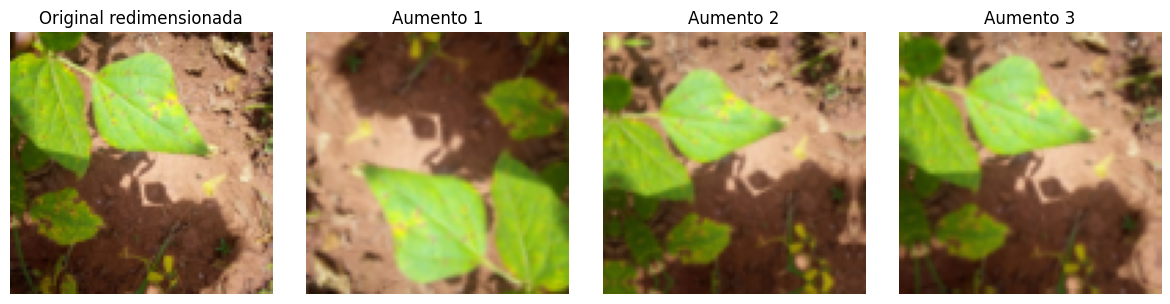

Preparación verificada: (1034, 96, 96, 3) (133, 96, 96, 3)


In [9]:
# Auditoría y preparación: no se evalúan predicciones de prueba.
from pathlib import Path
import hashlib
import json
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, log_loss)
from IPython.display import Markdown, display

OUT = Path('/content/resultados_cnn')
OUT.mkdir(parents=True, exist_ok=True)
IMG_SIZE = (96, 96)
BATCH_SIZE = 32
arrays, labels_by_split, hashes_by_split = {}, {}, {}
audit_rows = []
for split in ['train', 'validation', 'test']:
    resized, labels, hashes = [], [], []
    for example in beans[split]:
        pixels = np.asarray(example['image'].convert('RGB'), dtype=np.uint8)
        label = int(example['labels'])
        assert pixels.ndim == 3 and pixels.shape[2] == 3
        assert 0 <= label < num_classes
        digest = hashlib.sha256(str(pixels.shape).encode() + pixels.tobytes()).hexdigest()
        hashes.append(digest)
        resized.append(tf.image.resize(pixels, IMG_SIZE, antialias=True).numpy())
        labels.append(label)
    arrays[split] = np.asarray(resized, dtype=np.float32)
    labels_by_split[split] = np.asarray(labels, dtype=np.int64)
    hashes_by_split[split] = hashes
    assert np.isfinite(arrays[split]).all()
    assert arrays[split].shape == (split_sizes[split], *IMG_SIZE, 3)
    audit_rows.append({'Partición': split, 'Imágenes verificadas': len(labels),
                       'Duplicados exactos internos': len(hashes) - len(set(hashes))})

audit_table = pd.DataFrame(audit_rows)
display(audit_table)
for first, second in [('train','validation'), ('train','test'), ('validation','test')]:
    overlap = set(hashes_by_split[first]) & set(hashes_by_split[second])
    print(f'Duplicados entre {first} y {second}: {len(overlap)}')
    assert not overlap, 'Revisar particiones antes de entrenar.'

X_train_cnn, y_train_cnn = arrays['train'], labels_by_split['train']
X_val_cnn, y_val_cnn = arrays['validation'], labels_by_split['validation']
# No se calculan métricas en test hasta seleccionar la configuración.

def make_batches(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_batches(X_train_cnn, y_train_cnn, training=True)
val_ds = make_batches(X_val_cnn, y_val_cnn)

augmentation_preview = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    layers.RandomRotation(0.10, seed=SEED+1),
    layers.RandomZoom(0.10, seed=SEED+2)
], name='aumento_preview')

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(X_train_cnn[0].astype(np.uint8))
axes[0].set_title('Original redimensionada')
for i in range(1, 4):
    augmented = augmentation_preview(X_train_cnn[:1], training=True)[0].numpy()
    axes[i].imshow(np.clip(augmented, 0, 255).astype(np.uint8))
    axes[i].set_title(f'Aumento {i}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
print('Preparación verificada:', X_train_cnn.shape, X_val_cnn.shape)



EXPERIMENTO: CNN sin aumento


Model: "cnn_sin_aumento"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_rgb_0_255 (InputLayer)   │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion (Rescaling)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,939 (109.14 KB)

 Trainable params: 27,939 (109.14 KB)

 Non-trainable params: 0 (0.00 B)

... (5 outputs left out)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
33/33 - 10s - 312ms/step - accuracy: 0.3868 - loss: 1.0903 - val_accuracy: 0.4662 - val_loss: 1.0701
Epoch 2/30
33/33 - 10s - 309ms/step - accuracy: 0.4836 - loss: 1.0434 - val_accuracy: 0.5639 - val_loss: 0.9730
Epoch 3/30
33/33 - 10s - 293ms/step - accuracy: 0.5397 - loss: 0.9670 - val_accuracy: 0.6466 - val_loss: 0.8689
Epoch 4/30
33/33 - 8s - 254ms/step - accuracy: 0.5445 - loss: 0.9554 - val_accuracy: 0.5639 - val_loss: 0.8907
Epoch 5/30
33/33 - 8s - 254ms/step - accuracy: 0.5890 - loss: 0.9109 - val_accuracy: 0.6466 - val_loss: 0.8336
Epoch 6/30
33/33 - 8s - 245ms/step - accuracy: 0.6141 - loss: 0.8823 - val_accuracy: 0.5865 - val_loss: 0.8875
Epoch 7/30
33/33 - 10s - 301ms/step - accuracy: 0.6180 - loss: 0.8614 - val_accuracy: 0.6767 - val_loss: 0.7702
Epoch 8/30
33/33 - 10s - 308ms/step - accuracy: 0.6499 - loss: 0.8172 - val_accuracy: 0.6692 - val_loss: 0.7566
Epoch 9/30
33/33 - 10s - 308ms/step - accuracy: 0.6335 - loss: 0.8194 - val_accuracy: 0.6241 - val_loss: 0.

,Accuracy,Precision macro,Recall macro,F1 macro,Loss,Mejor época,Épocas ejecutadas
Modelo,,,,,,,
Clase mayoritaria,0.3383,0.1128,0.3333,0.1685,NaN,0,0
CNN sin aumento,0.7895,0.8192,0.7886,0.7796,0.5135,30,30
CNN con aumento,0.7820,0.7859,0.7822,0.7784,0.6000,30,30


CONFIGURACIÓN FIJADA ANTES DE PRUEBA: CNN sin aumento


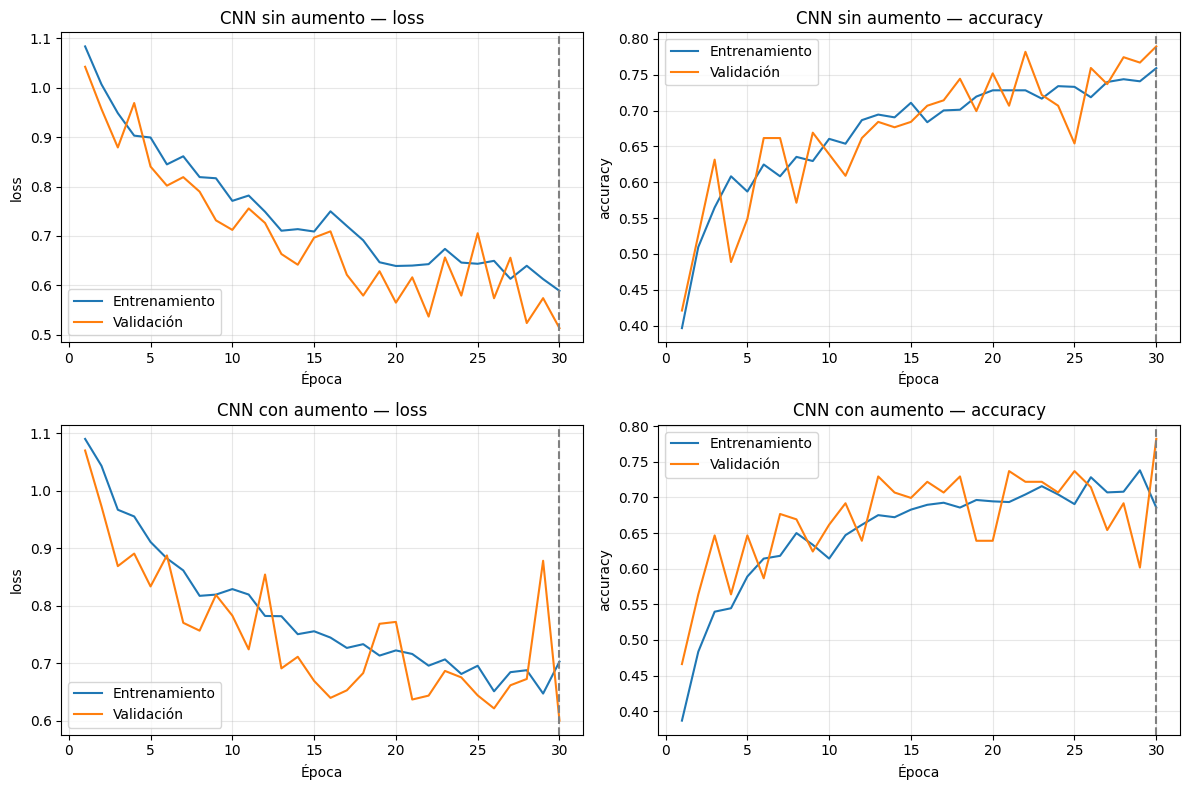

In [10]:
# Entrenamiento de dos configuraciones; selección solo con validación.
def build_cnn(use_augmentation=False):
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name='imagen_rgb_0_255')
    x = layers.Rescaling(1./255, name='normalizacion')(inputs)
    if use_augmentation:
        x = layers.RandomFlip('horizontal_and_vertical', seed=SEED)(x)
        x = layers.RandomRotation(0.10, seed=SEED+1)(x)
        x = layers.RandomZoom(0.10, seed=SEED+2)(x)
    for filters in [16, 32, 64]:
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3, seed=SEED+3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    model = keras.Model(inputs, outputs, name='cnn_con_aumento' if use_augmentation else 'cnn_sin_aumento')
    model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def classification_metrics(y_true, predictions):
    return {
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision macro': precision_score(y_true, predictions, average='macro', zero_division=0),
        'Recall macro': recall_score(y_true, predictions, average='macro', zero_division=0),
        'F1 macro': f1_score(y_true, predictions, average='macro', zero_division=0)
    }

majority_class = int(np.argmax(np.bincount(y_train_cnn, minlength=num_classes)))
val_rows = [{'Modelo': 'Clase mayoritaria',
             **classification_metrics(y_val_cnn, np.full(len(y_val_cnn), majority_class)),
             'Loss': np.nan, 'Mejor época': 0, 'Épocas ejecutadas': 0}]
models, histories, validation_probabilities = {}, {}, {}
for use_augmentation in [False, True]:
    keras.utils.set_random_seed(SEED)
    name = 'CNN con aumento' if use_augmentation else 'CNN sin aumento'
    model = build_cnn(use_augmentation)
    print('\nEXPERIMENTO:', name)
    model.summary()
    smoke = model(X_train_cnn[:2], training=False).numpy()
    assert smoke.shape == (2, num_classes) and np.isfinite(smoke).all()
    np.testing.assert_allclose(smoke.sum(axis=1), 1, atol=1e-5)
    tag = 'con_aumento' if use_augmentation else 'sin_aumento'
    checkpoint = OUT / f'{tag}.weights.h5'
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_loss',
                                        save_best_only=True, save_weights_only=True),
        keras.callbacks.TerminateOnNaN()
    ]
    history_run = model.fit(train_ds, validation_data=val_ds, epochs=30,
                            callbacks=callbacks, verbose=2)
    assert np.isfinite(history_run.history['loss']).all()
    model.load_weights(str(checkpoint))
    val_prob = model.predict(val_ds, verbose=0)
    assert np.isfinite(val_prob).all()
    models[name] = model
    histories[name] = history_run.history
    validation_probabilities[name] = val_prob
    val_rows.append({
        'Modelo': name, **classification_metrics(y_val_cnn, val_prob.argmax(axis=1)),
        'Loss': log_loss(y_val_cnn, val_prob, labels=list(range(num_classes))),
        'Mejor época': int(np.argmin(history_run.history['val_loss'])) + 1,
        'Épocas ejecutadas': len(history_run.history['loss'])
    })
    pd.DataFrame(history_run.history).to_csv(OUT / f'historial_{tag}.csv', index=False)

validation_results = pd.DataFrame(val_rows).set_index('Modelo')
display(validation_results.round(4))
selected_name = (validation_results.loc[list(models)]
                 .sort_values(['F1 macro', 'Loss'], ascending=[False, True]).index[0])
selected_model = models[selected_name]
print('CONFIGURACIÓN FIJADA ANTES DE PRUEBA:', selected_name)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, hist) in enumerate(histories.items()):
    for col, metric in enumerate(['loss', 'accuracy']):
        ax = axes[row, col]
        ep = np.arange(1, len(hist[metric]) + 1)
        ax.plot(ep, hist[metric], label='Entrenamiento')
        ax.plot(ep, hist['val_' + metric], label='Validación')
        ax.axvline(int(np.argmin(hist['val_loss'])) + 1, color='gray', linestyle='--')
        ax.set(title=f'{name} — {metric}', xlabel='Época', ylabel=metric)
        ax.legend()
        ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / 'curvas_entrenamiento.png', dpi=160)
plt.show()
validation_results.to_csv(OUT / 'comparacion_validacion.csv')


## 5. Evaluación final y análisis de errores

Se evaluará únicamente la CNN seleccionada con validación, junto con la referencia constante de entrenamiento. La decisión multiclase será argmax de softmax, sin ajustar reglas usando prueba. Se reportan pérdida, accuracy, precision/recall/F1 macro y métricas por clase. La matriz de confusión permite identificar qué enfermedades confunde el modelo.

Se mostrarán ejemplos correctos e incorrectos seleccionados con semilla fija; estas observaciones serán descriptivas y no se utilizarán para volver a ajustar el modelo. Las probabilidades softmax no se asumirán calibradas.

## 6. Guardado y reproducibilidad

Se guardan el modelo seleccionado, las métricas, los historiales, la configuración de preprocesamiento, las versiones de las dependencias, las predicciones y las gráficas en `/content/resultados_cnn`. Es una carpeta temporal del entorno de Colab: guardar el notebook no incorpora esos archivos. Los checkpoints permiten recuperar el mejor estado durante esta sesión. Se recargará el modelo y se comprobará que reproduce las predicciones.

Para ejecutar de nuevo: usar las celdas en orden desde la instalación. Esta implementación utiliza CPU y no requiere credenciales de Hugging Face. Una nueva ejecución puede variar por hardware o versiones, incluso con semilla fija. La evaluación repetida al ejecutar todo sirve para verificar reproducibilidad, no para seleccionar nuevos modelos con prueba.

RESULTADOS FINALES EN PRUEBA


,Accuracy,Precision macro,Recall macro,F1 macro,Loss
Clase mayoritaria,0.3359,0.1120,0.3333,0.1676,NaN
CNN sin aumento,0.7578,0.7554,0.7588,0.7562,0.5162


,precision,recall,f1-score,support
angular_leaf_spot,0.7619,0.7442,0.7529,43.0
bean_rust,0.7000,0.6512,0.6747,43.0
healthy,0.8043,0.8810,0.8409,42.0
macro avg,0.7554,0.7588,0.7562,128.0
weighted avg,0.7550,0.7578,0.7555,128.0


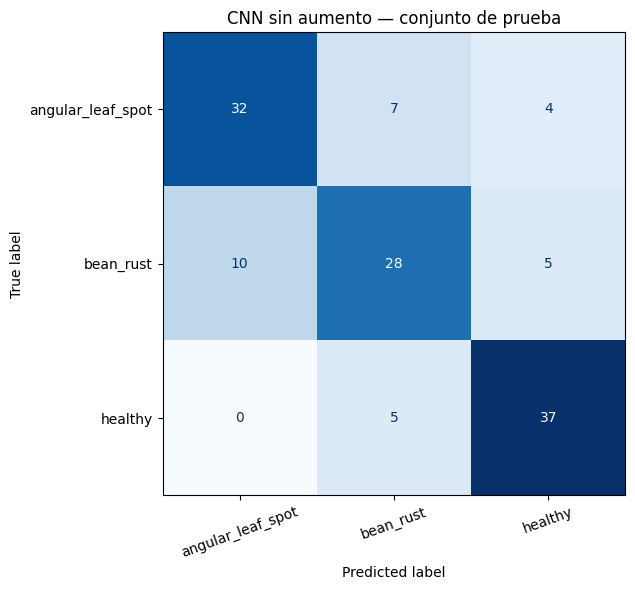

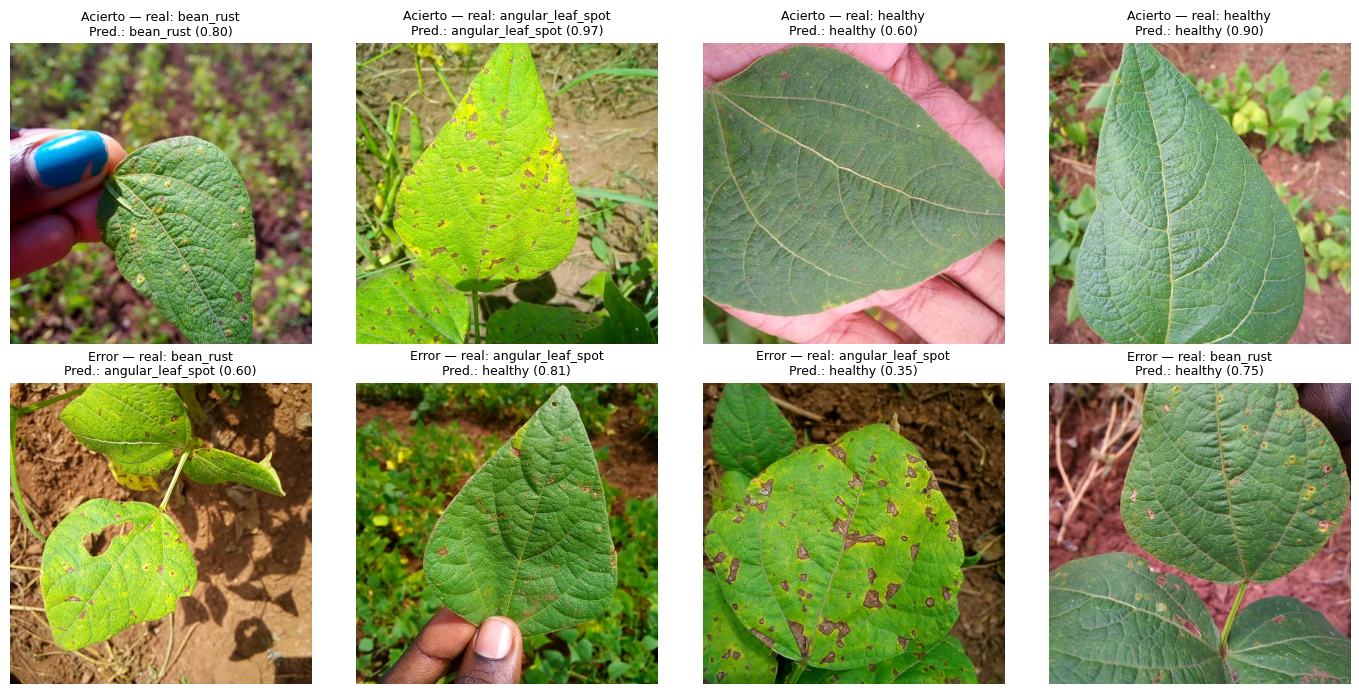

VERIFICACIÓN CORRECTA: probabilidades, métricas y recarga del modelo.


In [14]:
# Evaluación final: se ejecuta después de fijar selected_name con validación.
X_test_cnn, y_test_cnn = arrays['test'], labels_by_split['test']
test_ds = make_batches(X_test_cnn, y_test_cnn)
test_prob_cnn = selected_model.predict(test_ds, verbose=0)
assert test_prob_cnn.shape == (len(y_test_cnn), num_classes)
assert np.isfinite(test_prob_cnn).all()
np.testing.assert_allclose(test_prob_cnn.sum(axis=1), 1, atol=1e-5)
test_pred_cnn = test_prob_cnn.argmax(axis=1)
cnn_metrics = classification_metrics(y_test_cnn, test_pred_cnn)
cnn_metrics['Loss'] = log_loss(y_test_cnn, test_prob_cnn, labels=list(range(num_classes)))
constant_metrics = classification_metrics(y_test_cnn, np.full(len(y_test_cnn), majority_class))
test_results_cnn = pd.DataFrame([constant_metrics, cnn_metrics], index=['Clase mayoritaria', selected_name])
print('RESULTADOS FINALES EN PRUEBA')
display(test_results_cnn.round(4))
report = classification_report(y_test_cnn, test_pred_cnn, labels=list(range(num_classes)), target_names=class_names, output_dict=True, zero_division=0)
report_table = pd.DataFrame({k: v for k, v in report.items() if isinstance(v, dict)}).T
display(report_table.round(4))

cm = confusion_matrix(y_test_cnn, test_pred_cnn, labels=list(range(num_classes)))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'{selected_name} — conjunto de prueba')
plt.xticks(rotation=20)
fig.tight_layout()
fig.savefig(OUT / 'matriz_confusion_prueba.png', dpi=160)
plt.show()

rng = np.random.default_rng(SEED)
correct = np.flatnonzero(test_pred_cnn == y_test_cnn)
incorrect = np.flatnonzero(test_pred_cnn != y_test_cnn)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, (indices, title) in enumerate([(correct, 'Acierto'), (incorrect, 'Error')]):
    chosen = rng.choice(indices, size=min(4, len(indices)), replace=False)
    for col, ax in enumerate(axes[row]):
        ax.axis('off')
        if col < len(chosen):
            idx = int(chosen[col])
            ax.imshow(beans['test'][idx]['image'].convert('RGB'))
            ax.set_title(f'{title} — real: {class_names[y_test_cnn[idx]]}\nPred.: {class_names[test_pred_cnn[idx]]} ({test_prob_cnn[idx].max():.2f})', fontsize=9)
        else:
            ax.set_title('Sin más ejemplos disponibles')
fig.tight_layout()
fig.savefig(OUT / 'ejemplos_predicciones.png', dpi=160)
plt.show()

# Guardado y comprobación de recarga.
selected_model.save(OUT / 'cnn_beans.keras')
reloaded_model = keras.models.load_model(OUT / 'cnn_beans.keras', compile=False)
original_prob = selected_model.predict(X_val_cnn[:12], verbose=0)
reloaded_prob = reloaded_model.predict(X_val_cnn[:12], verbose=0)
np.testing.assert_allclose(original_prob, reloaded_prob, rtol=1e-5, atol=1e-6)
np.testing.assert_allclose(original_prob, selected_model.predict(X_val_cnn[:12], verbose=0), rtol=1e-5, atol=1e-6)

from importlib.metadata import version
packages = ['tensorflow', 'keras', 'datasets', 'Pillow', 'numpy', 'pandas', 'matplotlib', 'scikit-learn', 'h5py']
versions = {package: version(package) for package in packages}
config = {'dataset': DATASET_ID, 'seed': SEED, 'image_size': list(IMG_SIZE),
          'color_mode': 'RGB', 'resize': 'tf.image.resize bilinear antialias=True',
          'input_range': [0, 255], 'normalization': 'Rescaling(1/255) dentro del modelo',
          'classes': class_names, 'selection': selected_name,
          'selection_criterion': 'F1 macro validación; desempate menor loss',
          'batch_size': BATCH_SIZE, 'max_epochs': 30, 'early_stopping_patience': 7,
          'versions': versions,
          'dataset_fingerprints': {split: beans[split]._fingerprint for split in split_sizes}}
(OUT / 'configuracion.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT / 'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versions.items()) + '\n', encoding='utf-8')
test_results_cnn.to_csv(OUT / 'metricas_prueba.csv')
report_table.to_csv(OUT / 'metricas_por_clase.csv')
audit_table.to_csv(OUT / 'auditoria.csv', index=False)
prediction_table = pd.DataFrame({'real': y_test_cnn, 'prediccion': test_pred_cnn})
for class_id, name in enumerate(class_names):
    prediction_table['prob_' + name] = test_prob_cnn[:, class_id]
prediction_table.to_csv(OUT / 'predicciones_prueba.csv', index_label='indice_test')
manifest = [{'split': split, 'indice': i, 'sha256': digest} for split, hashes in hashes_by_split.items() for i, digest in enumerate(hashes)]
pd.DataFrame(manifest).to_csv(OUT / 'manifiesto_imagenes.csv', index=False)
print('VERIFICACIÓN CORRECTA: probabilidades, métricas y recarga del modelo.')


## 7. Conclusiones y límites del experimento

La siguiente celda genera las conclusiones con las métricas de esta ejecución para evitar cifras desactualizadas al volver a entrenar.

La ausencia de duplicados exactos no descarta imágenes parecidas ni observaciones relacionadas de una misma planta. Las fotografías muestran variaciones de fondo, manos e iluminación que podrían introducir sesgos. Reducir la resolución también puede perder detalles de lesiones.

Los resultados se limitan a una partición y semilla, con solo 128 imágenes de prueba. No se estudian significancia estadística, calibración ni generalización a otras regiones. El proyecto no constituye una herramienta de diagnóstico agrícola validada.

Como trabajo futuro se proponen mayor resolución, transfer learning, segmentación de hojas y evaluación por finca o planta con datos adicionales. Los cambios deberán elegirse con validación y evaluarse con un nuevo conjunto de prueba independiente; no se ajustará la CNN con los errores de prueba observados aquí.

In [15]:
# Resumen ligado a los resultados reales.
per_class_recall = {name: report[name]['recall'] for name in class_names}
weakest_class = min(per_class_recall, key=per_class_recall.get)
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
real_class, predicted_class = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
selected_hist = histories[selected_name]
best_ep = int(np.argmin(selected_hist['val_loss'])) + 1
augmentation_delta = (validation_results.loc['CNN con aumento', 'F1 macro']
                      - validation_results.loc['CNN sin aumento', 'F1 macro'])
conclusions = f'''### Resultados y aprendizajes

- Se implementaron dos CNN desde cero con **{selected_model.count_params():,} parámetros** cada una. Se verificaron todas las imágenes y no se encontraron duplicados exactos entre particiones.
- La configuración seleccionada fue **{selected_name}**, por F1 macro de validación. Incorporar aumento cambió F1 macro de validación en **{augmentation_delta:+.4f}**. Es un resultado de esta semilla y partición, no una garantía general del efecto del aumento.
- Los pesos seleccionados corresponden a la época **{best_ep}** de **{len(selected_hist['loss'])}** ejecutadas, según la menor pérdida de validación. La mejor época coincide con el límite de 30: no se demuestra convergencia completa; el presupuesto de entrenamiento se fijó antes de observar prueba. Las curvas permiten revisar la evolución de ambas pérdidas.
- En las **{len(y_test_cnn)} imágenes de prueba**, se obtuvo **accuracy {cnn_metrics['Accuracy']:.2%}**, **precision macro {cnn_metrics['Precision macro']:.4f}**, **recall macro {cnn_metrics['Recall macro']:.4f}**, **F1 macro {cnn_metrics['F1 macro']:.4f}** y **loss {cnn_metrics['Loss']:.4f}**.
- La referencia constante obtuvo accuracy **{constant_metrics['Accuracy']:.2%}** y F1 macro **{constant_metrics['F1 macro']:.4f}**. La comparación permite distinguir el aprendizaje de la CNN de predecir siempre una clase.
- Se clasificaron correctamente **{len(correct)}** imágenes y se cometieron **{len(incorrect)}** errores. La clase con menor recall fue **{weakest_class}** ({per_class_recall[weakest_class]:.2%}).
- La confusión fuera de la diagonal más frecuente fue **{class_names[real_class]} → {class_names[predicted_class]}**, con **{off_diagonal[real_class, predicted_class]}** casos. Los ejemplos ilustran aciertos y errores, pero no demuestran causalmente qué señales utiliza la red.
- Se aprendió a preparar imágenes, implementar convoluciones y aumento, conservar checkpoints y seleccionar configuraciones usando validación. La recarga del modelo reprodujo las predicciones con la tolerancia comprobada.
'''
display(Markdown(conclusions))
(OUT / 'conclusiones.md').write_text(conclusions, encoding='utf-8')
assert (OUT / 'cnn_beans.keras').stat().st_size > 0
assert len(prediction_table) == split_sizes['test']
required_files = ['cnn_beans.keras', 'configuracion.json', 'requirements.txt',
                  'metricas_prueba.csv', 'comparacion_validacion.csv',
                  'curvas_entrenamiento.png', 'matriz_confusion_prueba.png',
                  'ejemplos_predicciones.png', 'conclusiones.md']
assert all((OUT / name).is_file() for name in required_files)
print('VERIFICACIÓN FINAL CORRECTA: datos, resultados, modelo recargado y archivos.')
print('Archivos generados en:', OUT)
print(chr(10).join(sorted(p.name for p in OUT.iterdir())))


### Resultados y aprendizajes

- Se implementaron dos CNN desde cero con **27,939 parámetros** cada una. Se verificaron todas las imágenes y no se encontraron duplicados exactos entre particiones.
- La configuración seleccionada fue **CNN sin aumento**, por F1 macro de validación. Incorporar aumento cambió F1 macro de validación en **-0.0013**. Es un resultado de esta semilla y partición, no una garantía general del efecto del aumento.
- Los pesos seleccionados corresponden a la época **30** de **30** ejecutadas, según la menor pérdida de validación. La mejor época coincide con el límite de 30: no se demuestra convergencia completa; el presupuesto de entrenamiento se fijó antes de observar prueba. Las curvas permiten revisar la evolución de ambas pérdidas.
- En las **128 imágenes de prueba**, se obtuvo **accuracy 75.78%**, **precision macro 0.7554**, **recall macro 0.7588**, **F1 macro 0.7562** y **loss 0.5162**.
- La referencia constante obtuvo accuracy **33.59%** y F1 macro **0.1676**. La comparación permite distinguir el aprendizaje de la CNN de predecir siempre una clase.
- Se clasificaron correctamente **97** imágenes y se cometieron **31** errores. La clase con menor recall fue **bean_rust** (65.12%).
- La confusión fuera de la diagonal más frecuente fue **bean_rust → angular_leaf_spot**, con **10** casos. Los ejemplos ilustran aciertos y errores, pero no demuestran causalmente qué señales utiliza la red.
- Se aprendió a preparar imágenes, implementar convoluciones y aumento, conservar checkpoints y seleccionar configuraciones usando validación. La recarga del modelo reprodujo las predicciones con la tolerancia comprobada.


VERIFICACIÓN FINAL CORRECTA: datos, resultados, modelo recargado y archivos.
Archivos generados en: /content/resultados_cnn
auditoria.csv
cnn_beans.keras
comparacion_validacion.csv
con_aumento.weights.h5
conclusiones.md
configuracion.json
curvas_entrenamiento.png
ejemplos_predicciones.png
historial_con_aumento.csv
historial_sin_aumento.csv
manifiesto_imagenes.csv
matriz_confusion_prueba.png
metricas_por_clase.csv
metricas_prueba.csv
predicciones_prueba.csv
requirements.txt
sin_aumento.weights.h5
